In [ ]:
import pandas as pd


In [ ]:
data = pd.read_csv("/6G_Sports_Training_Categorical.csv")

In [ ]:
data.head()

,Athlete_ID,Heart_Rate_BPM,Acceleration_mps2,Latency_ms,Bandwidth_Usage_Mbps,CPU_Utilization_%,GPU_Utilization_%,AI_Optimized_Allocation_%,Packet_Loss_%,Training_Duration_min,TES_Category
0,1,162,2.341111,42.716429,97.275127,52.843398,77.973808,60.056827,3.948368,49,High Efficiency
1,2,111,2.835918,13.273813,48.811048,48.158671,72.855346,58.931444,3.694025,118,High Efficiency
2,3,152,2.813921,63.621319,41.276692,41.136689,46.237055,66.887400,3.126058,78,High Efficiency
3,4,74,1.627098,15.814647,14.531457,80.993963,38.364858,70.922475,4.931911,37,High Efficiency
4,5,166,0.783095,37.796199,14.748873,81.514681,36.899847,75.426945,2.667949,92,High Efficiency


In [ ]:
data.columns

Index(['Athlete_ID', 'Heart_Rate_BPM', 'Acceleration_mps2', 'Latency_ms',
       'Bandwidth_Usage_Mbps', 'CPU_Utilization_%', 'GPU_Utilization_%',
       'AI_Optimized_Allocation_%', 'Packet_Loss_%', 'Training_Duration_min',
       'TES_Category'],
      dtype='object')

In [ ]:
data["TES_Category"].value_counts()

,count
TES_Category,
High Efficiency,1491
Moderate Efficiency,9


In [ ]:
data["TES_Category"] = data["TES_Category"].replace({
    "High Efficiency": 1,
    "Moderate Efficiency": 0
})

/tmp/ipykernel_1482/1225639170.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data["TES_Category"] = data["TES_Category"].replace({


In [ ]:
data["TES_Category"].value_counts()

,count
TES_Category,
1,1491
0,9


In [ ]:
data = data.drop("Athlete_ID", axis=1)

In [ ]:
data.columns

Index(['Heart_Rate_BPM', 'Acceleration_mps2', 'Latency_ms',
       'Bandwidth_Usage_Mbps', 'CPU_Utilization_%', 'GPU_Utilization_%',
       'AI_Optimized_Allocation_%', 'Packet_Loss_%', 'Training_Duration_min',
       'TES_Category'],
      dtype='object')

In [ ]:
X = data.drop("TES_Category", axis=1)
y = data["TES_Category"]

In [ ]:
print(X.head())
print(y.head())

   Heart_Rate_BPM  Acceleration_mps2  Latency_ms  Bandwidth_Usage_Mbps  \
0             162           2.341111   42.716429             97.275127   
1             111           2.835918   13.273813             48.811048   
2             152           2.813921   63.621319             41.276692   
3              74           1.627098   15.814647             14.531457   
4             166           0.783095   37.796199             14.748873   

   CPU_Utilization_%  GPU_Utilization_%  AI_Optimized_Allocation_%  \
0          52.843398          77.973808                  60.056827   
1          48.158671          72.855346                  58.931444   
2          41.136689          46.237055                  66.887400   
3          80.993963          38.364858                  70.922475   
4          81.514681          36.899847                  75.426945   

   Packet_Loss_%  Training_Duration_min  
0       3.948368                     49  
1       3.694025                    118  
2       

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [16]:
print(X_train.shape)
print(X_test.shape)

(1200, 9)
(300, 9)


In [17]:
from sklearn.ensemble import RandomForestClassifier

In [18]:
model = RandomForestClassifier(class_weight="balanced", random_state=42)

In [19]:
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [20]:
y_pred = model.predict(X_test)

In [21]:
print(y_pred[:10])

[1 1 1 1 1 1 1 1 1 1]


In [22]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9966666666666667


In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[  0   1]
 [  0 299]]


In [24]:
!pip install imbalanced-learn

In [25]:
from imblearn.over_sampling import SMOTE

In [26]:
smote = SMOTE(random_state=42)

In [27]:
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [28]:
import pandas as pd
print(pd.Series(y_train_smote).value_counts())

TES_Category
1    1192
0    1192
Name: count, dtype: int64


In [29]:
model_smote = RandomForestClassifier(random_state=42)

model_smote.fit(X_train_smote, y_train_smote)

RandomForestClassifier(random_state=42)

In [30]:
y_pred_smote = model_smote.predict(X_test)

In [31]:
from sklearn.metrics import accuracy_score

accuracy_smote = accuracy_score(y_test, y_pred_smote)

print("Accuracy with SMOTE:", accuracy_smote)

Accuracy with SMOTE: 0.9966666666666667


In [32]:
from sklearn.metrics import confusion_matrix

cm_smote = confusion_matrix(y_test, y_pred_smote)

print(cm_smote)

[[  1   0]
 [  1 298]]


In [33]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       1.00      1.00      1.00       299

    accuracy                           1.00       300
   macro avg       0.75      1.00      0.83       300
weighted avg       1.00      1.00      1.00       300



In [34]:
import pandas as pd

feature_importance = pd.Series(
    model_smote.feature_importances_,
    index=X.columns
)

print(feature_importance.sort_values(ascending=False))

Packet_Loss_%                0.393416
Latency_ms                   0.328133
AI_Optimized_Allocation_%    0.153652
CPU_Utilization_%            0.066560
Acceleration_mps2            0.034259
Bandwidth_Usage_Mbps         0.008783
GPU_Utilization_%            0.008328
Training_Duration_min        0.004019
Heart_Rate_BPM               0.002850
dtype: float64


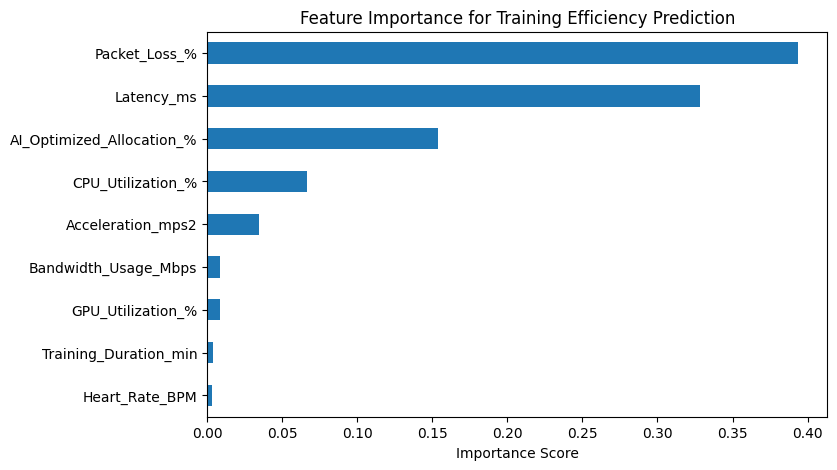

In [35]:
import matplotlib.pyplot as plt

feature_importance.sort_values().plot(
    kind='barh',
    figsize=(8,5)
)

plt.title("Feature Importance for Training Efficiency Prediction")
plt.xlabel("Importance Score")
plt.show()

In [36]:
import joblib

joblib.dump(model_smote, "training_efficiency_model.pkl")

['training_efficiency_model.pkl']

In [37]:
from google.colab import files

files.download("training_efficiency_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>